# Telco Customer Churn Prediction

**Goal:** Predict whether a telecom customer is likely to churn (leave) or stay.

Dataset: [Telco Customer Churn on Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Before running:** Download the CSV from Kaggle and place `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the same folder as this notebook.

## 1. Import libraries

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

print('Libraries imported successfully.')

Libraries imported successfully.


In [24]:
pip install pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Load the dataset

In [25]:
file_name = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(file_name)

print('Dataset shape:', df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the data

In [26]:
print('Column names:')
print(df.columns.tolist())
print('\nData types and non-null values:')
df.info()
print('\nMissing values in each column:')
display(df.isnull().sum())
print('\nChurn distribution:')
display(df['Churn'].value_counts())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecur

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

## 4. Clean the data

In [27]:
# Convert TotalCharges to numbers. Blank values become missing values.
file_name = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Convert target labels: Yes = 1 (Churn), No = 0 (Stay)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# CustomerID is an identifier, so it is not used as a predictive feature.
df = df.drop(columns=['customerID'])
df = df.dropna(subset=['Churn'])

print('Data cleaning completed.')
print('Dataset shape after cleaning:', df.shape)
print('Missing TotalCharges values:', df['TotalCharges'].isnull().sum())

Data cleaning completed.
Dataset shape after cleaning: (7043, 20)
Missing TotalCharges values: 11


## 5. Select input features and target

Features include tenure, contract, monthly charges, internet service, support services and payment method. The target is `Churn`.

In [28]:
X = df.drop(columns=['Churn'])
y = df['Churn']

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numeric_features = X.select_dtypes(exclude=['object']).columns.tolist()

print('Numeric features:', numeric_features)
print('\nCategorical features:', categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\Admin\AppData\Local\Temp\ipykernel_20604\1681438782.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


## 6. Split data into training and testing sets

Use 80% of the data to train the model and 20% to test it.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 5634
Testing rows: 1409


## 7. Prepare data and build the model

In [30]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

model.fit(X_train, y_train)
print('Model training completed.')

Model training completed.


## 8. Predict churn and probability

In [31]:
y_pred = model.predict(X_test)
churn_probability = model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results['Actual_Churn'] = y_test
results['Predicted_Churn'] = y_pred
results['Churn_Probability'] = churn_probability.round(3)
results['Prediction'] = results['Predicted_Churn'].map({
    0: 'Likely to Stay',
    1: 'Likely to Churn'
})

results.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Prediction
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0,0.115,Likely to Stay
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.853,Likely to Churn
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0,0.147,Likely to Stay
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,Month-to-month,No,Electronic check,78.20,1468.75,0,1,0.661,Likely to Churn
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0,0.060,Likely to Stay
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,0,1,0.806,Likely to Churn
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40,0,1,0.698,Likely to Churn
2976,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,...,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20,0,0,0.294,Likely to Stay
5928,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,...,No internet service,Two year,No,Credit card (automatic),19.75,1311.60,0,0,0.009,Likely to Stay
1639,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,Month-to-month,Yes,Electronic check,45.05,770.60,1,1,0.653,Likely to Churn


In [32]:
pip install pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 9. Evaluate model performance

In [33]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f'Accuracy : {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall   : {recall:.3f}')
print(f'F1-score : {f1:.3f}')

print('\nClassification report:')
print(classification_report(y_test, y_pred, target_names=['Stay', 'Churn'], zero_division=0))

Accuracy : 0.738
Precision: 0.504
Recall   : 0.783
F1-score : 0.614

Classification report:
              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## 10. Confusion matrix and business questions

Correctly identified churn customers (True Positives): 293
Churn customers missed (False Negatives): 81
Non-churn customers wrongly flagged as churn (False Positives): 288
Non-churn customers correctly identified (True Negatives): 747


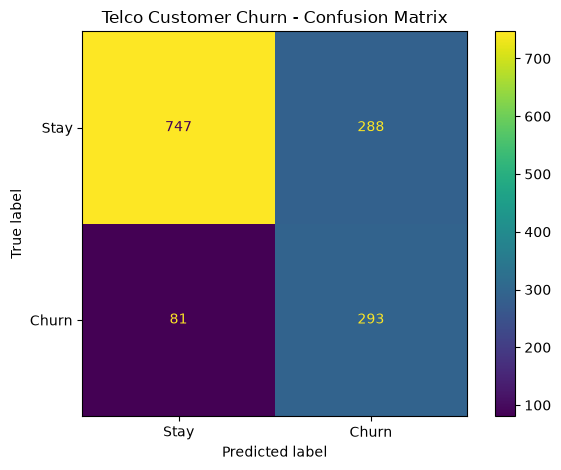

In [34]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print('Correctly identified churn customers (True Positives):', tp)
print('Churn customers missed (False Negatives):', fn)
print('Non-churn customers wrongly flagged as churn (False Positives):', fp)
print('Non-churn customers correctly identified (True Negatives):', tn)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stay', 'Churn']).plot()
plt.title('Telco Customer Churn - Confusion Matrix')
plt.tight_layout()
plt.show()

## 11. Predict unseen customer records

Edit the example rows below if you want to try different customers. The columns must match the dataset's input columns (except `customerID` and `Churn`).

In [35]:
new_customers = pd.DataFrame([
    {
        'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No',
        'tenure': 2, 'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'DSL',
        'OnlineSecurity': 'No', 'OnlineBackup': 'Yes', 'DeviceProtection': 'No',
        'TechSupport': 'No', 'StreamingTV': 'No', 'StreamingMovies': 'No',
        'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
        'PaymentMethod': 'Electronic check', 'MonthlyCharges': 55.50, 'TotalCharges': 111.00
    },
    {
        'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes',
        'tenure': 60, 'PhoneService': 'Yes', 'MultipleLines': 'Yes', 'InternetService': 'Fiber optic',
        'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes', 'DeviceProtection': 'Yes',
        'TechSupport': 'Yes', 'StreamingTV': 'Yes', 'StreamingMovies': 'Yes',
        'Contract': 'Two year', 'PaperlessBilling': 'No',
        'PaymentMethod': 'Bank transfer (automatic)', 'MonthlyCharges': 95.20, 'TotalCharges': 5712.00
    }
])

new_predictions = model.predict(new_customers)
new_probabilities = model.predict_proba(new_customers)[:, 1]
new_customers['Prediction'] = pd.Series(new_predictions).map({0: 'Likely to Stay', 1: 'Likely to Churn'})
new_customers['Churn_Probability'] = new_probabilities.round(3)
new_customers

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Prediction,Churn_Probability
0,Female,0,No,No,2,Yes,No,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,55.5,111.0,Likely to Churn,0.671
1,Male,0,Yes,Yes,60,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),95.2,5712.0,Likely to Stay,0.123


## 12. Save results

In [36]:
results.to_csv('churn_predictions.csv', index=False)
print('Saved test predictions to churn_predictions.csv')

Saved test predictions to churn_predictions.csv


## 13. Business interpretation and improvement

- **False Negative:** A customer actually leaves, but the model predicts they will stay. This may cause lost revenue because the company misses a retention opportunity.
- **False Positive:** A customer would stay, but the model flags them as likely to churn. The company may spend money on an unnecessary offer.
- **Business priority:** Missing a real churn customer is often more costly, so pay attention to churn recall. The best threshold should be chosen using actual retention-offer costs and customer value.
- **One improvement:** Compare this model with Random Forest or XGBoost, then tune the decision threshold using validation data to improve churn detection without excessive unnecessary offers.